# Лабораторная работа № 1
## Иерархический кластерный анализ

**Вариант 2 — Economics of Cities**

### Цель работы

Определить количество кластеров городов на основе экономических показателей, распределить города по полученным группам и предложить интерпретацию кластеров.

### Постановка задачи

Провести иерархическую кластеризацию 48 городов мира по показателям продолжительности рабочего времени, уровня цен и почасовой заработной платы. Обосновать выбор количества кластеров и проанализировать полученные группы.

### Описание данных

Набор данных содержит экономические показатели 48 городов мира за 1991 год:

- **City** — название города;
- **Work** — средневзвешенное количество рабочих часов по 12 профессиям;
- **Price** — индекс цен на 112 товаров и услуг, включая аренду жилья;
- **Salary** — индекс почасовой заработной платы после налогов и вычетов по 12 профессиям.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv(
    "/content/Econom_Cities_data.csv",
    sep=";",
    decimal=","
)
df.head()

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


In [5]:
# Информация о данных
df.info()
print(df.isna().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   City    48 non-null     object 
 1   Work    48 non-null     int64  
 2   Price   48 non-null     float64
 3   Salary  48 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 1.6+ KB
City      0
Work      0
Price     0
Salary    0
dtype: int64


,Work,Price,Salary
count,48.000000,48.000000,48.000000
mean,1384.958333,68.860417,-378.727083
std,2404.897007,21.784659,2027.338052
min,-9999.000000,30.300000,-9999.000000
25%,1740.750000,49.650000,12.250000
50%,1834.500000,70.500000,40.300000
75%,1972.750000,81.700000,58.700000
max,2375.000000,115.500000,100.000000


In [6]:
df[(df[["Work", "Price", "Salary"]] < 0).any(axis=1)]

,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


Первоначальная проверка показала, что набор содержит 48 наблюдений и 4 переменные. Все столбцы имеют корректные типы данных, стандартные пропуски (NaN) отсутствуют.

При анализе описательной статистики были выявлены значения -9999 в признаках Work и Salary для двух городов — Cairo и Jakarta.

In [7]:
df_clean = df.drop(
    df[(df["Work"] == -9999) | (df["Salary"] == -9999)].index
).copy()

После очистки данных проведём визуальный анализ показателей.
Для этого построим гистограммы распределений признаков Work, Price и Salary. Это позволит оценить диапазоны значений, особенности распределений и возможное наличие выбросов.

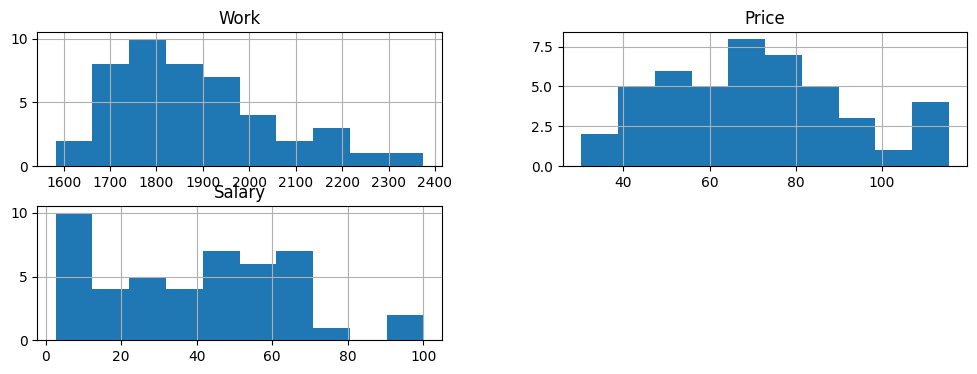

In [8]:
features = ["Work", "Price", "Salary"]

df_clean[features].hist(figsize=(12, 4), bins=10)
plt.show()

**Work:** большинство городов имеет примерно 1650–2000 рабочих часов. Распределение смещено вправо, встречаются отдельные значения до 2400 часов.

**Price:** индекс цен изменяется примерно от 30 до 115. Наибольшая концентрация городов наблюдается в диапазоне 60–80.

**Salary:** индекс заработной платы имеет значительный разброс — примерно от 3 до 100. Заметна концентрация городов с низкими зарплатами (до 20), а также в диапазоне 40–70.

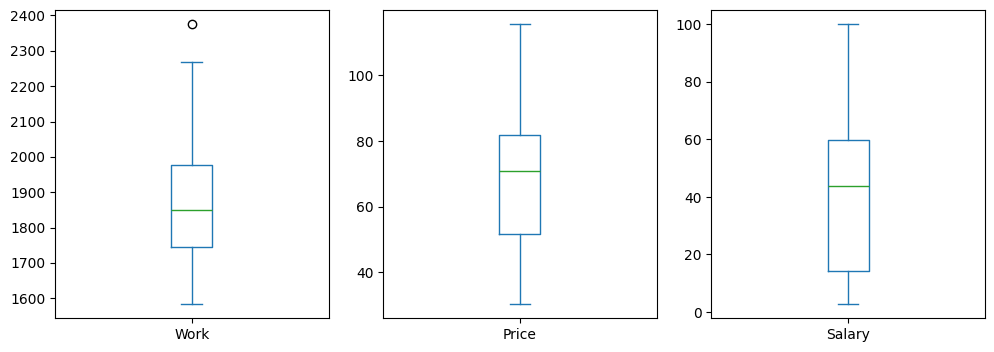

In [9]:
df_clean[features].plot(
    kind="box",
    subplots=True,
    layout=(1, 3),
    figsize=(12, 4)
)
plt.show()

**Распределения и выбросы**
Показатели городов имеют различные диапазоны значений. На Boxplot обнаружен один потенциальный выброс по признаку Work. Для Price и Salary потенциальных выбросов не выявлено. Наблюдение с высоким Work пока оставил, поскольку его значение не обязательно говорит об ошибке.

In [10]:
corr_matrix = df_clean[features].corr()

corr_matrix.round(2)

,Work,Price,Salary
Work,1.00,-0.45,-0.46
Price,-0.45,1.00,0.80
Salary,-0.46,0.80,1.00


**Взаимосвязи признаков**
Между Price и Salary наблюдается сильная положительная корреляция (0.80). Признак Work имеет умеренную отрицательную корреляцию с Price (−0.45) и Salary (−0.46).

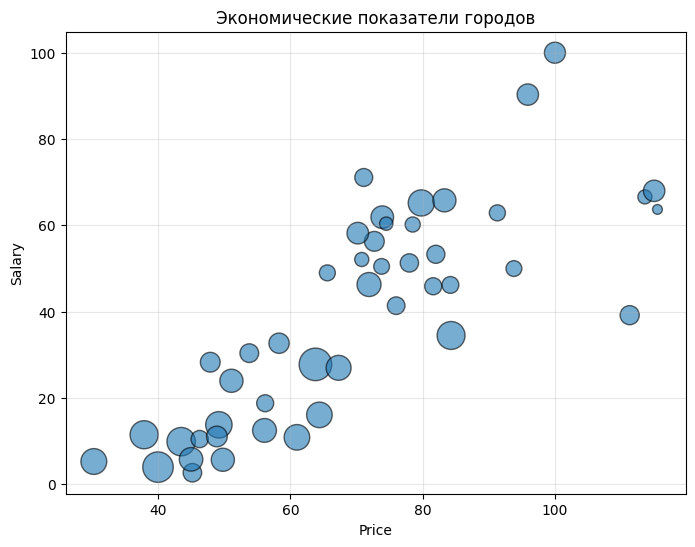

In [11]:
work = df_clean["Work"]
sizesMM = 50 + (work - work.min()) / (work.max() - work.min()) * 500

plt.figure(figsize=(8, 6))

plt.scatter(
    df_clean["Price"],
    df_clean["Salary"],
    s=sizesMM,
    alpha=0.6,
    edgecolors="black"
)

plt.xlabel("Price")
plt.ylabel("Salary")
plt.title("Экономические показатели городов")
plt.grid(alpha=0.3)
plt.show()


**Пузырьковая диаграмма**
Города с низкими ценами и зарплатами преимущественно имеют более крупные пузырьки, что указывает на относительно высокое количество рабочих часов. Для городов с более высокими зарплатами и ценами чаще характерны меньшие значения.

Перед кластеризацией выполним стандартизацию признаков Work, Price и Salary методом Z-score. Это позволяет использовать их совместно при проведении кластерного анализа.

In [12]:
X = df_clean[features]
X_scaled = (X - X.mean()) / X.std()
print(X_scaled.describe().round(2))
X_scaled.head()

        Work  Price  Salary
count  46.00  46.00   46.00
mean    0.00  -0.00    0.00
std     1.00   1.00    1.00
min    -1.70  -1.86   -1.49
25%    -0.77  -0.86   -1.02
50%    -0.18   0.04    0.17
75%     0.55   0.55    0.81
max     2.84   2.12    2.44


,Work,Price,Salary
0,-0.951650,-0.210387,0.381875
1,-0.504255,-0.762068,-0.369406
2,1.560646,-1.505434,-1.132805
3,0.987062,-1.860754,-1.383232
4,-0.986065,0.172985,0.442462


**Иерархический кластерный анализ**

Для разделения городов на группы со схожими экономическими характеристиками используем иерархическую кластеризацию методом Уорда.

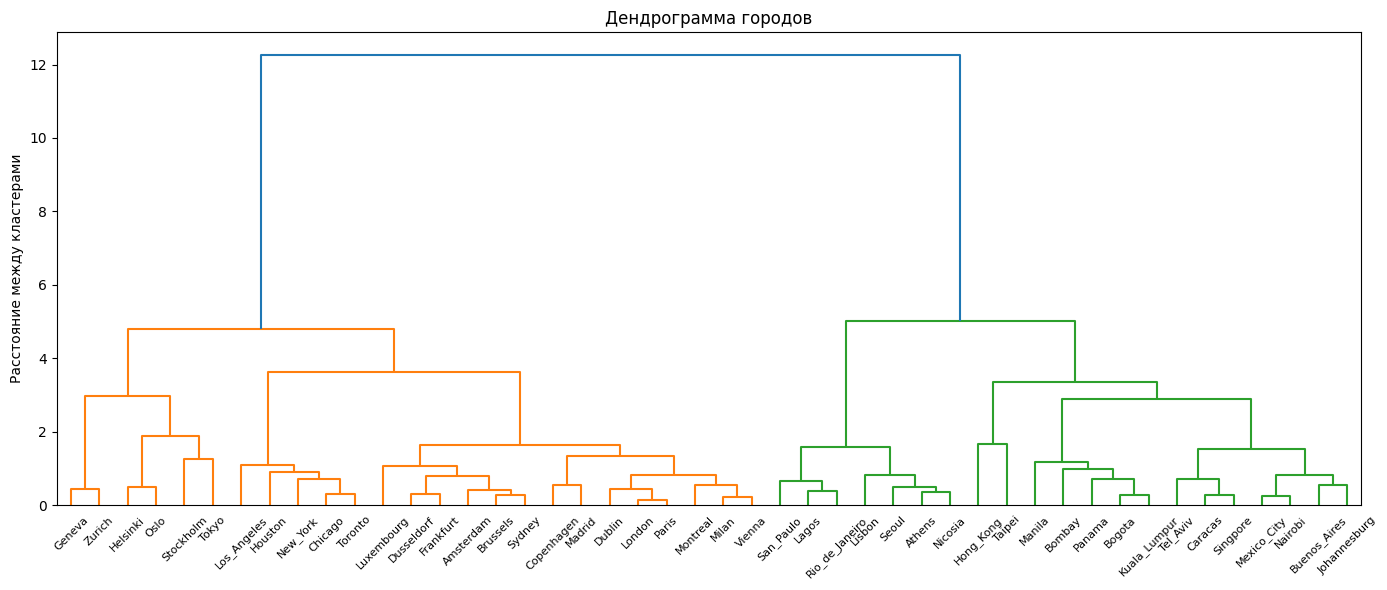

In [13]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

link = linkage(X_scaled, 'ward', 'euclidean')

plt.figure(figsize=(14, 6))
dendrogram(link, labels=df_clean["City"].tolist(),
           leaf_rotation=45)

plt.title("Дендрограмма городов")
plt.ylabel("Расстояние между кластерами")
plt.tight_layout()
plt.show()

Дендрограмма показывает два крупных объединения групп городов. Последнее объединение происходит на значительно большей высоте, чем предыдущие, что позволяет предположить наличие двух основных кластеров.

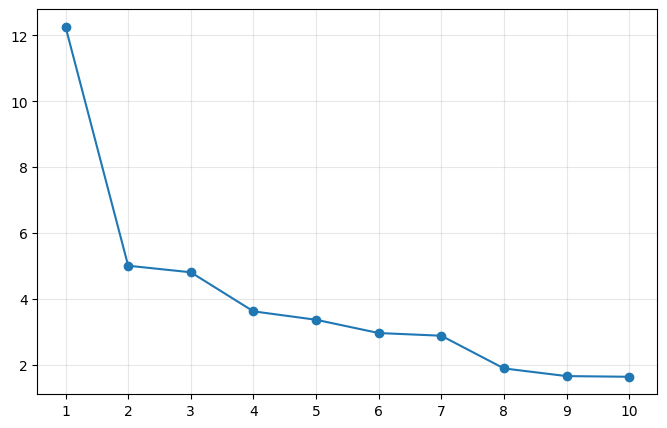

In [14]:
distances = link[-10:, 2]

plt.figure(figsize=(8, 5))
plt.plot(range(10, 0, -1), distances, marker="o")

plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

На графике каменистой осыпи наблюдается наиболее выраженный скачок высоты объединения при переходе от двух кластеров к одному. Это указывает на существенные различия между двумя крупными группами городов.

In [15]:
clusters = fcluster(link, t=2, criterion="maxclust")

df_irarh = df_clean.copy()
df_irarh["Cluster"] = clusters
df_irarh.head(5)

,City,Work,Price,Salary,Cluster
0,Amsterdam,1714,65.6,49.0,1
1,Athens,1792,53.8,30.4,2
2,Bogota,2152,37.9,11.5,2
3,Bombay,2052,30.3,5.3,2
4,Brussels,1708,73.8,50.5,1


In [16]:
cluster_means_irarh = df_irarh.groupby("Cluster")[features].mean().round(2)
cluster_means_irarh

,Work,Price,Salary
Cluster,,,
1,1789.24,84.97,59.03
2,1987.86,52.40,16.35


В результате иерархической кластеризации были выделены два кластера:

Кластер 1: преимущественно города с высокими зарплатами и ценами, средняя продолжительность рабочего года — 1789 часов.

Кластер 2: города с более низкими зарплатами и ценами, средняя продолжительность рабочего года — 1988 часов.

Различие заключается в том, что в первом кластере индекс почасовой зарплаты почти в 4 раза выше, а продолжительность рабочего года почти на 200 часов меньше. При этом в первой группе разница между индексами цен и зарплат сравнительно небольшая, тогда как во второй она значительно заметнее.
